# Какие признаки помогают прогнозировать отток абонентов?

**Кейс 2 · Telco Customer Churn v1 · Исследование от 19 ноября 2026**

Модель должна оценивать вероятность `Churn = Yes` у абонента и помогать объяснять, какие характеристики связаны с высоким риском. Сравниваем логистическую регрессию на исходных полях с несколькими наборами новых признаков и со случайным лесом. Используем тот же снимок из 7 043 абонентов, который изучала команда. [Постановка кейса](../context/case-02.md) · [Общий EDA, раздел 8](01_eda.ipynb) · [Журнал решений](../docs/decisions.md)

> Кандидат для команды — логистическая регрессия со стажем в двух формах, исходной и логарифмической. Во всех пяти внешних разбиениях процедура выбрала вариант без накопленной суммы начислений.

Для воспроизведения выполните `uv sync --locked` в корне проекта, подготовьте локальный CSV и запустите все ячейки в ядре этого окружения. Ноутбук работает из корня и из папки `notebooks/`. [Получение CSV и проверка SHA-256](../data/README.md)

## Что предложили проверить опубликованные решения

| Источник | Что сделали авторы | Как проверяем в этом исследовании |
|---|---|---|
| [S. Saleh и S. Saha, *SN Applied Sciences*, 2023](https://link.springer.com/article/10.1007/s42452-023-05389-6) | Авторы сравнили пять алгоритмов на четырёх наборах. На IBM Telco логистическая регрессия лидировала по AUC, случайный лес — по precision. | Сравниваем обе модели и оцениваем долю ушедших как при пороге 0,50, так и среди 10% наиболее рискованных абонентов. |
| [IBM, Telco customer churn](https://github.com/IBM/telco-customer-churn-on-icp4d) | Авторы закодировали категории и обучили случайный лес на полях абонента. | Сравниваем лес и логистическую регрессию на одних внешних фолдах. |
| [gcmarques00, Churn prediction pipeline](https://github.com/gcmarques00/churn-prediction-pipeline) | Сгруппировал абонентов по стажу и рассчитал средние начисления за месяц обслуживания. | Проверяем плавную кривизну связи со стажем через `log1p(tenure)` и отдельным опытом добавляем разность между текущей и средней платой. |
| [Telco Customer Churn, код признаков](https://github.com/siyu0125/Telco-Customer-Churn/blob/main/src/pipeline.py) | Авторы рассчитали число подключённых опций и сопоставили текущую плату со средней. | Сохраняем конкретные услуги и отдельно проверяем, даёт ли дополнительную информацию размер пакета. |

Метрики ниже рассчитаны на разбиениях этого ноутбука. Из командного EDA взяли ещё две гипотезы — срок договора может менять связь риска со стажем, а основные услуги позволяют восстановить смысл специальных категорий в полях опций.

## 1. Выборка и протокол

Отводим 20% абонентов под итоговую оценку команды. В исследовании используем оставшиеся 80%. Разбиение стратифицировано по `Churn` с `random_state=42`. В исходном EDA команда уже рассматривала весь снимок, в том числе связи с целью. Даже будущая оценка на этих 20% будет внутренней проверкой на том же источнике.

На исследовательской части создаём пять общих стратифицированных фолдов. Для каждой логистической модели на обучающей части внешнего фолда выбираем силу L2-регуляризации по трём внутренним фолдам. Там же выбираем набор признаков. Внешний фолд оценивает всю процедуру выбора. Каждый абонент получает одну вероятность от модели, обученной на других абонентах. Далее называем её вневыборочной вероятностью, OOF. [Пример вложенной кросс-валидации в scikit-learn](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)

Основная метрика для выбора — **ROC-AUC**. При доле оттока около 27% дополнительно измеряем **average precision (AP)**, ступенчатое обобщение кривой precision–recall. Для самих вероятностей считаем **Brier score** (среднюю квадратичную ошибку вероятности) и **log loss**. У обеих ошибок меньшее значение лучше. Баланс классов сохраняем. Метрики и разбиение пока имеют статус предложения. [Журнал](../docs/decisions.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src.data import load_raw

SEED = 42
raw = load_raw()
assert raw["customerID"].is_unique and raw["Churn"].isin(["No", "Yes"]).all()
dev_ids, holdout_ids = train_test_split(
    raw.index, test_size=0.20, stratify=raw["Churn"], random_state=SEED
)
assert pd.Index(dev_ids).intersection(holdout_ids).empty
X = raw.loc[dev_ids].drop(columns=["Churn", "customerID"])
y = raw.loc[dev_ids, "Churn"].eq("Yes").astype(int)
outer_splits = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
inner_cv = StratifiedKFold(3, shuffle=True, random_state=SEED + 1)
print(f"Исследование: {len(X)} абонента, ушли {y.sum()} ({y.mean():.2%}).")
print(f"Резерв: {len(holdout_ids)} абонентов. Исходных признаков: {X.shape[1]}.")

Исследование: 5634 абонента, ушли 1495 (26.54%).
Резерв: 1409 абонентов. Исходных признаков: 19.


## 2. Конструирование признаков

| Вариант | Отличие от исходных полей | Проверяемая гипотеза |
|---|---|---|
| Без накопленных начислений | Убираем `TotalCharges`. Повторяем опыт после добавления логарифма стажа. | Стаж и текущий тариф могут объяснять большую часть информации в накопленной сумме. |
| Кривая стажа | К исходному `tenure` добавляем `log(1 + tenure)`. | Один месяц разницы может сильнее менять прогноз у нового абонента, чем у давнего. |
| Кодирование услуг | Объединяем специальные значения отсутствия основной услуги с `No` в семи полях опций. Сохраняем `InternetService` и `PhoneService`. | В общей модели тип основной услуги позволяет различить отказ от опции и отсутствие доступа к ней. |
| Размер пакета | При том же кодировании группируем число подключённых интернет-опций в 0, 1–2 и 3–6. | У размера пакета может быть дополнительная нелинейная связь с оттоком. |
| Разница начислений | `MonthlyCharges − TotalCharges / tenure` при положительном стаже. | Отклонение от средней за весь срок может быть связано с оттоком. Для вывода о повышении тарифа потребовалась бы история цен. |
| Стаж × договор | У годовых и двухлетних договоров появляется своя поправка к коэффициенту логарифма стажа. | Связь со стажем может различаться по типам договора. |

Для базовой обработки подставляем 0 только при одновременно пустом `TotalCharges` и нулевом стаже. В журнале это предложено как допущение для новых клиентов. Для разницы начислений при нулевом стаже нет определённого значения. Здесь и для других числовых пропусков используем медиану обучающего фолда. [EDA, разделы 2 и 8](01_eda.ipynb) · [Предложение по TotalCharges](../docs/decisions.md)

In [2]:
ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
          "StreamingTV", "StreamingMovies"]

# Порядок задаёт приоритет при близком качестве на внутренних фолдах.
FEATURE_SETS = {
    "Исходные без TotalCharges": ("drop_total",),
    "Исходные": (),
    "Кривая стажа без TotalCharges": ("log_tenure", "drop_total"),
    "Кривая стажа": ("log_tenure",),
    "Стаж + кодирование услуг": ("log_tenure", "service_flags"),
    "Стаж + размер пакета": ("log_tenure", "service_flags", "bundle"),
    "Стаж + разница начислений": ("log_tenure", "charge_gap"),
    "Стаж × договор": ("log_tenure", "contract_slopes"),
    "Все блоки": ("log_tenure", "service_flags", "bundle", "charge_gap", "contract_slopes"),
}


def make_features(frame, blocks):
    out = frame.copy()
    tenure = out["tenure"]
    if "drop_total" in blocks:
        out = out.drop(columns="TotalCharges", errors="ignore")
    else:
        missing_new = out["TotalCharges"].isna() & tenure.eq(0)
        out.loc[missing_new, "TotalCharges"] = 0

    if "log_tenure" in blocks:
        out["log_tenure"] = np.log1p(tenure)
    if "service_flags" in blocks:
        out[ADDONS] = out[ADDONS].replace("No internet service", "No")
        out["MultipleLines"] = out["MultipleLines"].replace("No phone service", "No")
    if "bundle" in blocks:
        count = out[ADDONS].eq("Yes").sum(axis=1).where(out[ADDONS].notna().all(axis=1))
        out["addon_band"] = pd.cut(count, [-1, 0, 2, 6], labels=["0", "1–2", "3–6"])
    if "charge_gap" in blocks:
        monthly_average = out["TotalCharges"].div(tenure.where(tenure.gt(0)))
        out["charge_gap"] = out["MonthlyCharges"] - monthly_average
    if "contract_slopes" in blocks:
        for contract in ["One year", "Two year"]:
            out[f"log_tenure_{contract}"] = out["log_tenure"] * out["Contract"].eq(contract)
    return out

In [3]:
# Две искусственные строки проверяют правило заполнения и деление при нулевом стаже.
probe = X.iloc[:2].copy()
probe["tenure"] = [0, 12]
probe["TotalCharges"] = [np.nan, np.nan]
check = make_features(probe, FEATURE_SETS["Все блоки"])
assert check["TotalCharges"].iloc[0] == 0 and pd.isna(check["TotalCharges"].iloc[1])
assert check["charge_gap"].isna().all() and probe["TotalCharges"].isna().all()

example = make_features(X, FEATURE_SETS["Все блоки"])
display(example[["tenure", "log_tenure", "MonthlyCharges", "TotalCharges",
                 "charge_gap", "addon_band"]].head(4).round(2))

,tenure,log_tenure,MonthlyCharges,TotalCharges,charge_gap,addon_band
3738,35,3.58,49.20,1701.65,0.58,3–6
3151,15,2.77,75.10,1151.55,-1.67,1–2
4860,13,2.64,40.55,590.35,-4.86,3–6
3867,26,3.30,73.50,1905.70,0.20,3–6


## 3. Обучение и выбор модели

Числовые поля, включая бинарный `SeniorCitizen`, проходят через заполнение медианой и стандартизацию. Для категорий используем подстановку моды и one-hot-кодирование. Все параметры предобработки оцениваются внутри `Pipeline` заново на каждом обучающем фолде. Столбцы `Churn` и `customerID` исключены до обучения.

Для каждого из девяти наборов признаков проверяем `C ∈ {0.1, 1, 10}`. Чем меньше `C`, тем сильнее регуляризация. Варианты перечислены от наиболее простых для воспроизведения. Берём первый, чья средняя внутренняя ROC-AUC отстаёт от лучшей не более чем на 0,001. Допуск 0,001 задан до расчёта как практическая граница для выбора более простого варианта.

Два ориентира — постоянная вероятность, равная доле ушедших на обучающем фолде, и случайный лес на исходных полях (240 деревьев, минимум 8 наблюдений в листе). Параметры леса зафиксированы для этого сравнения. Все модели видят одни и те же внешние обучающие и проверочные строки.

In [4]:
def make_pipeline(blocks, estimator):
    numeric = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    encode = ColumnTransformer([
        ("num", numeric, make_column_selector(dtype_include=np.number)),
        ("cat", categorical, make_column_selector(dtype_exclude=np.number)),
    ])
    return Pipeline([
        ("features", FunctionTransformer(make_features, kw_args={"blocks": blocks})),
        ("encode", encode),
        ("model", estimator),
    ])


def tune_strength(estimator, x_train, y_train):
    search = GridSearchCV(
        estimator, {"model__C": [0.1, 1.0, 10.0]},
        cv=inner_cv, scoring="roc_auc", error_score="raise",
    )
    return search.fit(x_train, y_train)


def fit_logistic_variants(x_train, y_train):
    searches = {}
    for name, blocks in FEATURE_SETS.items():
        estimator = make_pipeline(blocks, LogisticRegression(max_iter=1000, tol=1e-6))
        searches[name] = tune_strength(estimator, x_train, y_train)
    best_score = max(search.best_score_ for search in searches.values())
    choice = next(name for name, search in searches.items()
                  if search.best_score_ >= best_score - 0.001)
    return searches, choice


def metrics(y_true, probability):
    return {
        "ROC-AUC": roc_auc_score(y_true, probability),
        "AP": average_precision_score(y_true, probability),
        "Brier": brier_score_loss(y_true, probability),
        "Log loss": log_loss(y_true, probability),
    }

In [5]:
PRIOR = "Постоянная вероятность"
FOREST = "Случайный лес"
SELECTED = "Логистическая регрессия с отбором"
oof = pd.DataFrame(index=X.index, columns=[PRIOR, FOREST, *FEATURE_SETS, SELECTED], dtype=float)
fold_scores, fold_choices, outer_models = [], [], []

for fold, (train_pos, valid_pos) in enumerate(outer_splits, start=1):
    x_train, y_train = X.iloc[train_pos], y.iloc[train_pos]
    x_valid, y_valid = X.iloc[valid_pos], y.iloc[valid_pos]
    searches, choice = fit_logistic_variants(x_train, y_train)
    models = {name: search.best_estimator_ for name, search in searches.items()}
    outer_models.append(models[choice])
    fold_choices.append({"Фолд": fold, "Набор": choice, "C": searches[choice].best_params_["model__C"]})
    models[PRIOR] = DummyClassifier(strategy="prior").fit(x_train, y_train)
    forest = RandomForestClassifier(n_estimators=240, min_samples_leaf=8, n_jobs=2, random_state=SEED)
    models[FOREST] = make_pipeline((), forest).fit(x_train, y_train)

    for name, model in models.items():
        probability = model.predict_proba(x_valid)[:, 1]
        oof.loc[x_valid.index, name] = probability
    oof.loc[x_valid.index, SELECTED] = oof.loc[x_valid.index, choice]
    for name in oof.columns:
        probability = oof.loc[x_valid.index, name]
        fold_scores.append({"Фолд": fold, "Модель": name, **metrics(y_valid, probability)})

assert oof.notna().all().all() and oof.ge(0).all().all() and oof.le(1).all().all()
scores = pd.DataFrame(fold_scores)
aucs = scores.pivot(index="Фолд", columns="Модель", values="ROC-AUC")
delta = aucs.subtract(aucs["Исходные"], axis="index")
summary = scores.groupby("Модель")[["ROC-AUC", "AP", "Brier", "Log loss"]].mean()
summary["SD ROC-AUC"] = aucs.std()
summary["Δ ROC к исходным"] = delta.mean()
display(summary.loc[[PRIOR, "Исходные", *[n for n in FEATURE_SETS if n != "Исходные"],
                     FOREST, SELECTED]].round(4))
choices = pd.DataFrame(fold_choices).set_index("Фолд")
choices["ROC-AUC на внешнем фолде"] = aucs[SELECTED]
choices["Δ к исходным"] = delta[SELECTED]
display(choices.round(4))

,ROC-AUC,AP,Brier,Log loss,SD ROC-AUC,Δ ROC к исходным
Модель,,,,,,
Постоянная вероятность,0.5000,0.2654,0.1949,0.5786,0.0000,-0.3464
Исходные,0.8464,0.6609,0.1349,0.4165,0.0143,0.0000
Исходные без TotalCharges,0.8449,0.6586,0.1355,0.4174,0.0136,-0.0015
Кривая стажа без TotalCharges,0.8503,0.6725,0.1330,0.4105,0.0130,0.0039
Кривая стажа,0.8502,0.6726,0.1330,0.4105,0.0130,0.0038
Стаж + кодирование услуг,0.8503,0.6730,0.1329,0.4104,0.0129,0.0039
Стаж + размер пакета,0.8503,0.6719,0.1330,0.4107,0.0130,0.0039
Стаж + разница начислений,0.8496,0.6710,0.1333,0.4112,0.0128,0.0032
Стаж × договор,0.8508,0.6733,0.1328,0.4098,0.0130,0.0044


,Набор,C,ROC-AUC на внешнем фолде,Δ к исходным
Фолд,,,,
1,Кривая стажа без TotalCharges,1.0,0.8455,-0.0031
2,Кривая стажа без TotalCharges,10.0,0.8327,0.0075
3,Кривая стажа без TotalCharges,10.0,0.8469,0.0057
4,Кривая стажа без TotalCharges,10.0,0.8638,0.0003
5,Кривая стажа без TotalCharges,10.0,0.8627,0.0093


По средним пяти внешних фолдов логистическая регрессия на исходных полях получила ROC-AUC 0,8464 и AP 0,6609. Добавление логарифма стажа подняло их до 0,8502 и 0,6726. После этого исключение `TotalCharges` практически сохранило обе метрики (0,8503 и 0,6725). Вариант со взаимодействием стажа и договора дал наибольшую среднюю ROC-AUC (0,8508), но выигрыш перед простой кривой стажа составил около 0,0006. После компактного кодирования услуг добавление размера пакета сохранило ROC-AUC на уровне 0,8503, а AP снизилась с 0,6730 до 0,6719. Вариант с разницей начислений дал 0,8496 и 0,6710.

Во всех пяти внутренних отборах победил вариант с логарифмом стажа без `TotalCharges` по заранее заданному правилу близости. Для всей процедуры выбора внешняя ROC-AUC равна 0,8503 при межфолдовом SD 0,0130. Выбранный вариант опередил исходную модель на четырёх из пяти фолдов. Парные разницы ROC-AUC составили от −0,0031 до +0,0093. Случайный лес с фиксированными параметрами дал в среднем 0,8466. В колонке Δ каждая модель сравнивается с исходной логистической регрессией на тех же фолдах.

## 4. Насколько вероятности совпадают с наблюдаемым оттоком

Сортируем вневыборочные прогнозы логистической модели с выбором признаков и делим абонентов на десять равных по размеру групп. Для каждой группы сравниваем среднюю вероятность и долю фактически ушедших. Чем ближе точка к диагонали, тем лучше согласуются эти величины. [Оценка калибровки в scikit-learn](https://scikit-learn.org/stable/modules/calibration.html)

,Абоненты,Ушли,Прогноз,Отток
Дециль,,,,
1,564,7,0.8%,1.2%
2,563,10,2.1%,1.8%
3,563,31,4.3%,5.5%
4,564,49,8.1%,8.7%
5,563,78,14.3%,13.9%
6,563,133,22.8%,23.6%
7,564,172,32.4%,30.5%
8,563,250,44.8%,44.4%
9,563,334,58.9%,59.3%


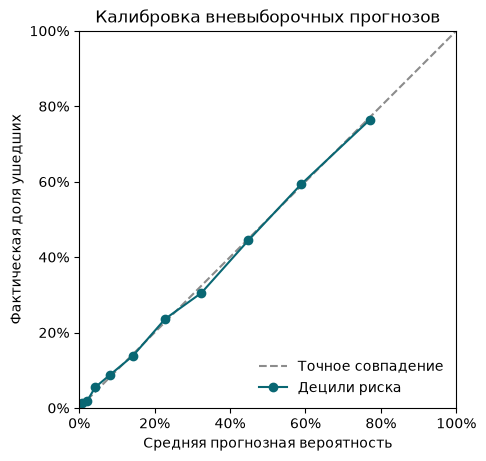

In [6]:
probability = oof[SELECTED]
risk = pd.DataFrame({"Прогноз": probability, "Исход": y})
risk["Дециль"] = pd.qcut(probability, q=10, labels=False) + 1
bins = risk.groupby("Дециль").agg(
    Абоненты=("Исход", "size"), Ушли=("Исход", "sum"),
    Прогноз=("Прогноз", "mean"), Отток=("Исход", "mean"),
)
display(bins.style.format({"Прогноз": "{:.1%}", "Отток": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(5.8, 4.5), layout="constrained")
ax.plot([0, 1], [0, 1], linestyle="--", color="0.55", label="Точное совпадение")
ax.plot(bins["Прогноз"], bins["Отток"], "o-", color="#096773", label="Децили риска")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Средняя прогнозная вероятность",
       ylabel="Фактическая доля ушедших", title="Калибровка вневыборочных прогнозов")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_aspect("equal", adjustable="box")
ax.legend(frameon=False, loc="lower right")
plt.show()

В верхнем дециле средняя прогнозная вероятность составила 77,1%, а ушёл 431 из 564 абонентов (76,4%). В нижнем дециле модель прогнозировала 0,8%, фактически ушли 7 из 564 (1,2%). Brier score снизился с 0,1349 у исходной логистической регрессии до 0,1330 у модели с отбором признаков. График показывает согласованность по группам в пределах исследованного снимка.

In [7]:
# Два сценария применения одного набора OOF-вероятностей без подбора порога.
top_count = int(np.ceil(0.10 * len(y)))
top_ids = probability.sort_values(ascending=False, kind="stable").head(top_count).index
rules = {
    "Вероятность ≥ 0,50": probability.ge(0.5),
    "10% с наибольшим риском": probability.index.isin(top_ids),
}
actions = []
for name, flagged in rules.items():
    n = int(np.sum(flagged))
    tp = int(y[flagged].sum())
    precision = tp / n if n else np.nan
    actions.append({"Правило": name, "Отобраны": n, "Ушли в группе": tp,
                    "Ложные тревоги": n - tp, "Пропущены": int(y.sum() - tp),
                    "Precision": precision, "Recall": tp / y.sum(), "Lift": precision / y.mean()})
display(pd.DataFrame(actions).set_index("Правило").round(3))

,Отобраны,Ушли в группе,Ложные тревоги,Пропущены,Precision,Recall,Lift
Правило,,,,,,,
"Вероятность ≥ 0,50",1195,807,388,688,0.675,0.540,2.545
10% с наибольшим риском,564,431,133,1064,0.764,0.288,2.880


При пороге 0,50 модель отметила 1 195 абонентов и обнаружила 807 из 1 495 уходов (полнота 54,0%, точность 67,5%). Если бюджет позволяет связаться с 564 абонентами, верхние 10% списка содержат 431 ушедшего, то есть 28,8% всех уходов. Доля ушедших в этом списке в 2,88 раза выше фоновой. Для выбора рабочего порога нужны стоимость контакта и ожидаемый эффект удержания.

## 5. Какие характеристики связаны с высоким риском

По очереди исключаем одну группу исходных полей и все вычисленные из неё признаки. Например, вместе со стажем убираем его логарифм и взаимодействия с договором. Оставляем набор преобразований, выбранный по обучающей части соответствующего внешнего фолда, и заново подбираем `C` для сокращённого набора на внутренних фолдах. Сравниваем ROC-AUC и AP на тех же внешних абонентах.

Такой опыт оценивает, сколько предсказательной информации добавляет группа при наличии остальных полей. Взаимозаменяемые поля могут компенсировать друг друга. Направление связи смотрим отдельно по наблюдаемым и вневыборочным прогнозным долям оттока в группах абонентов.

In [8]:
# Для каждой группы перечислены исходные поля и все зависимые производные признаки.
slopes = ["log_tenure_One year", "log_tenure_Two year"]
omissions = {
    "Стаж и накопленные начисления": ["tenure", "TotalCharges", "log_tenure", "charge_gap", *slopes],
    "Месячная плата и услуги": ["MonthlyCharges", "PhoneService", "MultipleLines", "InternetService",
                       *ADDONS, "charge_gap", "addon_band"],
    "Тип договора": ["Contract", *slopes],
    "Оплата и тип счёта": ["PaymentMethod", "PaperlessBilling"],
    "Профиль абонента": ["gender", "SeniorCitizen", "Partner", "Dependents"],
}

drops = []
for fold, ((train_pos, valid_pos), model) in enumerate(zip(outer_splits, outer_models), start=1):
    x_valid, y_valid = X.iloc[valid_pos], y.iloc[valid_pos]
    full = metrics(y_valid, oof.loc[x_valid.index, SELECTED])
    for group, cols in omissions.items():
        reduced = clone(model)
        omit = FunctionTransformer(pd.DataFrame.drop, kw_args={"columns": cols, "errors": "ignore"})
        # Удаляем столбцы после расчёта производных и до заполнения, кодирования и обучения.
        reduced.steps.insert(1, ("omit", omit))
        fitted = tune_strength(reduced, X.iloc[train_pos], y.iloc[train_pos])
        without = metrics(y_valid, fitted.predict_proba(x_valid)[:, 1])
        drops.append({"Фолд": fold, "Группа": group, "Δ ROC-AUC": full["ROC-AUC"] - without["ROC-AUC"],
                      "Δ AP": full["AP"] - without["AP"]})

impact = pd.DataFrame(drops).groupby("Группа").agg(**{
    "Падение ROC-AUC": ("Δ ROC-AUC", "mean"), "Падение AP": ("Δ AP", "mean"),
    "Мин. по ROC-AUC": ("Δ ROC-AUC", "min"), "Макс. по ROC-AUC": ("Δ ROC-AUC", "max"),
})
display(impact.sort_values("Падение ROC-AUC", ascending=False).round(4))

,Падение ROC-AUC,Падение AP,Мин. по ROC-AUC,Макс. по ROC-AUC
Группа,,,,
Месячная плата и услуги,0.0274,0.0601,0.0092,0.0362
Стаж и накопленные начисления,0.0183,0.0617,0.0137,0.0269
Тип договора,0.0072,0.0070,0.0044,0.0093
Оплата и тип счёта,0.0033,0.0058,-0.0009,0.0064
Профиль абонента,-0.0000,-0.0005,-0.0007,0.0009


In [9]:
profiles = {
    "Договор": X["Contract"],
    "Стаж, месяцев": pd.cut(X["tenure"], [-1, 6, 24, np.inf], labels=["0–6", "7–24", "25+"]),
    "Интернет": X["InternetService"],
    "Способ оплаты": X["PaymentMethod"],
}
profile_tables = {}
for label, values in profiles.items():
    table = risk.groupby(values, observed=True).agg(
        Абоненты=("Исход", "size"), Ушли=("Исход", "sum"),
        Отток=("Исход", "mean"), Прогноз=("Прогноз", "mean"),
    )
    profile_tables[label] = table
profile_table = pd.concat(profile_tables, names=["Признак", "Группа"])
display(profile_table.style.format({"Отток": "{:.1%}", "Прогноз": "{:.1%}"}))

Наибольшая потеря ROC-AUC после переобучения связана с исключением услуг вместе с месячной платой (−0,0274), затем идут стаж (−0,0183) и тип договора (−0,0072). У выбранной модели накопленная сумма уже исключена, поэтому во второй группе вклад даёт стаж в двух формах. Для способа оплаты и типа счёта потеря составила 0,0033, для демографического профиля — около нуля.

В исследовательских данных при стаже до полугода ушли 611 из 1 170 абонентов (52,2%), при стаже от 25 месяцев — 439 из 3 079 (14,3%). По помесячным договорам ушли 1 326 из 3 102 (42,7%), по двухлетним — 39 из 1 359 (2,9%). По оптоволоконному подключению доля составила 42,1%, по DSL — 18,7%. В таблице видны также исходные размеры групп и средние вневыборочные прогнозы. Эти группы различаются и по другим характеристикам. Для оценки эффекта смены тарифа или договора понадобились бы дополнительные данные.

## 6. Обучение исследовательской модели

Применяем то же правило выбора по трём фолдам ко всем 5 634 исследовательским строкам. `GridSearchCV` уже переобучает лучший вариант каждого набора на всех переданных строках. Извлекаем выбранный конвейер и проверяем, что он принимает исходные поля. Для нового абонента `predict_proba` возвращает вероятность ухода в столбце класса 1.

In [10]:
final_searches, final_name = fit_logistic_variants(X, y)
final_model = final_searches[final_name].best_estimator_
assert list(final_model.classes_) == [0, 1]
print(f"Набор признаков: {final_name}. C = {final_model.named_steps['model'].C:g}.")
print(f"Всего обучающих строк: {len(X)}. Отложено для команды: {len(holdout_ids)}.")

# Пример вызова на трёх известных строках. Эти числа иллюстрируют интерфейс прогноза.
example_risk = final_model.predict_proba(X.iloc[:3])[:, 1]
display(pd.Series(example_risk, index=["Абонент A", "Абонент B", "Абонент C"],
                  name="Вероятность ухода").to_frame().style.format("{:.1%}"))

Набор признаков: Кривая стажа без TotalCharges. C = 10.
Всего обучающих строк: 5634. Отложено для команды: 1409.


,Вероятность ухода
Абонент A,32.9%
Абонент B,21.7%
Абонент C,2.2%


Из девяти вариантов логистической регрессии для продолжения экспериментов предлагаем сохранить `tenure`, добавить `log1p(tenure)` и исключить `TotalCharges`. На всей исследовательской части по внутренней проверке выбрано `C=10`. Статус предложения и основание зафиксированы в [журнале решений](../docs/decisions.md).

Цель в снимке — уход за последний месяц. Проверка качества на будущем календарном периоде потребует дат расчёта признаков и последующих наблюдений об уходе. Итоговый резерв из 1 409 клиентов остаётся доступен для проверки зафиксированной командой спецификации.

## 7. Сколько услуг подключено и какие основные услуги выбрал абонент

В первом сравнении «размер пакета» означал три диапазона числа **шести интернет-опций**. Здесь считаем все доступные в CSV услуги по отдельности. За точку отсчёта берём выбранную ранее логистическую регрессию с `tenure` и `log1p(tenure)` без `TotalCharges`. Отдельные поля услуг остаются в модели.

- **Число услуг** — по одной за телефонию, интернет, опцию нескольких телефонных линий и каждую из шести подключённых интернет-опций. `MultipleLines = Yes` добавляет единицу независимо от фактического числа линий. Значения `No`, `No internet service` и `No phone service` добавляют ноль. Проверяем числовой счётчик и вариант, в котором модель может присвоить каждому размеру пакета свой коэффициент.
- **Только интернет** означает подключённый интернет при отсутствии телефонии. **Только телефон** означает телефонию при отсутствии интернета. У обеих групп могут быть свои дополнительные опции. В отдельном опыте уточняем смысл слова «только» до **ровно одной услуги**, исключая все опции, в том числе несколько линий.
- В описании IBM `Phone Service` означает домашний телефон. Для гипотезы о мобильной связи в этом CSV потребовалось бы отдельное поле. [Словарь IBM, раздел Services](https://community.ibm.com/community/user/blogs/steven-macko/2019/07/11/telco-customer-churn-1113)

Используем те же 5 634 строки и пять внешних фолдов. Для каждого варианта повторяем подбор `C` на трёх внутренних фолдах. Сравнение парное, с той же проверочной группой в каждой паре. Новые гипотезы предложены после первого исследования этих фолдов. 1 409 отложенных строк зарезервированы для итоговой проверки команды.

In [11]:
def service_features(frame):
    phone = frame["PhoneService"].eq("Yes")
    internet = frame["InternetService"].ne("No")
    known = frame[["PhoneService", "InternetService"]].notna().all(axis=1)
    options = frame[["MultipleLines", *ADDONS]]
    n_options = options.eq("Yes").sum(axis=1).where(options.notna().all(axis=1))
    count = (phone.astype(float) + internet.astype(float) + n_options).where(known)

    internet_only = internet & ~phone
    phone_only = phone & ~internet
    return pd.DataFrame({
        "service_count": count,
        "service_count_category": count.astype("Int64").astype("str"),
        "internet_only": internet_only.astype(float).where(known),
        "phone_only": phone_only.astype(float).where(known),
        "internet_alone": (internet_only & count.eq(1)).astype(float).where(count.notna()),
        "phone_alone": (phone_only & count.eq(1)).astype(float).where(count.notna()),
    }, index=frame.index)


def add_service_features(frame, columns):
    return frame.join(service_features(frame)[list(columns)])


services = service_features(X)
assert services.notna().all().all() and services["service_count"].between(1, 9).all()
both = X["PhoneService"].eq("Yes") & X["InternetService"].ne("No")
neither = X["PhoneService"].eq("No") & X["InternetService"].eq("No")
groups = {
    "Интернет без телефона": services["internet_only"].eq(1),
    "Телефон без интернета": services["phone_only"].eq(1),
    "Интернет и телефон": both,
    "Из первой группы, ровно одна услуга": services["internet_alone"].eq(1),
    "Из второй группы, ровно одна услуга": services["phone_alone"].eq(1),
}
print(f"Без обеих основных услуг: {neither.sum()} из {len(X)}.")
by_type = pd.DataFrame([
    {"Группа": name, "Абоненты": int(mask.sum()), "Ушли": int(y[mask].sum()), "Доля ухода": y[mask].mean()}
    for name, mask in groups.items()
]).set_index("Группа")
by_count = y.groupby(services["service_count"].astype(int).rename("Число услуг")).agg(
    Абоненты="size", Ушли="sum", Доля="mean",
)
display(by_type.style.format({"Доля ухода": "{:.1%}"}))
display(by_count.style.format({"Доля": "{:.1%}"}))

Без обеих основных услуг: 0 из 5634.


,Абоненты,Ушли,Доля ухода
Группа,,,
Интернет без телефона,559,135,24.2%
Телефон без интернета,1214,88,7.2%
Интернет и телефон,3861,1272,32.9%
"Из первой группы, ровно одна услуга",63,27,42.9%
"Из второй группы, ровно одна услуга",935,78,8.3%


,Абоненты,Ушли,Доля
Число услуг,,,
1,998,105,10.5%
2,704,218,31.0%
3,645,283,43.9%
4,777,285,36.7%
5,741,241,32.5%
6,724,189,26.1%
7,552,127,23.0%
8,319,39,12.2%
9,174,8,4.6%


In [12]:
REFERENCE = "Кривая стажа без TotalCharges"
service_trials = {
    "Число услуг": ("service_count",),
    "Только интернет": ("internet_only",),
    "Только телефон": ("phone_only",),
    "Оба флага": ("internet_only", "phone_only"),
    "Число услуг и оба флага": ("service_count", "internet_only", "phone_only"),
    "Число услуг как категория": ("service_count_category",),
    "Оба флага ровно одной услуги": ("internet_alone", "phone_alone"),
}

# Базовые оценки уже посчитаны в разделе 3 на тех же строках.
service_rows = scores.loc[scores["Модель"].eq(REFERENCE)].to_dict("records")
for name, columns in service_trials.items():
    estimator = make_pipeline(FEATURE_SETS[REFERENCE], LogisticRegression(max_iter=1000, tol=1e-6))
    add_columns = FunctionTransformer(add_service_features, kw_args={"columns": columns})
    estimator.steps.insert(0, ("service_package", add_columns))
    for fold, (train_pos, valid_pos) in enumerate(outer_splits, start=1):
        fitted = tune_strength(estimator, X.iloc[train_pos], y.iloc[train_pos])
        prob = fitted.predict_proba(X.iloc[valid_pos])[:, 1]
        service_rows.append({"Фолд": fold, "Модель": name, **metrics(y.iloc[valid_pos], prob)})

service_scores = pd.DataFrame(service_rows)
auc_by_fold = service_scores.pivot(index="Фолд", columns="Модель", values="ROC-AUC")
paired = auc_by_fold.subtract(auc_by_fold[REFERENCE], axis="index")
service_results = service_scores.groupby("Модель")[["ROC-AUC", "AP", "Brier", "Log loss"]].mean()
service_results["Δ ROC-AUC"] = paired.mean()
service_results["Δ AP"] = service_results["AP"] - service_results.loc[REFERENCE, "AP"]
display(service_results.loc[[REFERENCE, *service_trials]].round(5))
display(paired[list(service_trials)].T.set_axis(
    [f"Фолд {fold}" for fold in paired.index], axis=1,
).round(5))

,ROC-AUC,AP,Brier,Log loss,Δ ROC-AUC,Δ AP
Модель,,,,,,
Кривая стажа без TotalCharges,0.85034,0.67252,0.13297,0.41049,0.00000,0.00000
Число услуг,0.85036,0.67260,0.13296,0.41048,0.00002,0.00007
Только интернет,0.85041,0.67267,0.13292,0.41040,0.00007,0.00015
Только телефон,0.85036,0.67257,0.13296,0.41048,0.00002,0.00004
Оба флага,0.85036,0.67260,0.13297,0.41048,0.00003,0.00008
Число услуг и оба флага,0.85038,0.67260,0.13296,0.41048,0.00004,0.00008
Число услуг как категория,0.84964,0.67037,0.13333,0.41156,-0.00070,-0.00215
Оба флага ровно одной услуги,0.85000,0.67198,0.13307,0.41112,-0.00034,-0.00054


,Фолд 1,Фолд 2,Фолд 3,Фолд 4,Фолд 5
Модель,,,,,
Число услуг,0.00002,-0.00003,0.00006,0.00006,-0.00001
Только интернет,0.00033,-0.00001,0.00002,0.00002,-0.00000
Только телефон,0.00003,-0.00002,0.00003,0.00004,-0.00000
Оба флага,0.00004,-0.00004,0.00006,0.00006,-0.00000
Число услуг и оба флага,0.00003,-0.00003,0.00009,0.00008,0.00002
Число услуг как категория,0.00029,-0.00007,-0.00107,-0.00110,-0.00152
Оба флага ровно одной услуги,0.00017,0.00011,-0.00159,-0.00016,-0.00025


Общее число услуг описывает неоднородные группы. При одной услуге ушли 105 из 998 абонентов (10,5%), при трёх — 283 из 645 (43,9%), при девяти — 8 из 174 (4,6%). Отдельно по основным услугам доля ухода составила 24,2% для интернета без телефона, 7,2% для телефона без интернета и 32,9% при обеих услугах. В узкой группе «один интернет без опций» всего 63 человека, из них ушли 27. На проценты влияют состав пакета и характеристики абонентов.

В прогнозе по пяти фолдам базовая ROC-AUC равна 0,85034. Добавление числового счётчика дало 0,85036, отдельного флага «только интернет» — 0,85041, «только телефон» — 0,85036. Счётчик вместе с двумя флагами дал 0,85038. Средний парный прирост этой комбинации составил 0,00004 по ROC-AUC и 0,00008 по AP. Нелинейное кодирование числа услуг по отдельным значениям снизило ROC-AUC до 0,84964, а строгие флаги «ровно одна услуга» дали 0,85000.

У всех 5 634 абонентов есть телефон, интернет или обе услуги. Поэтому здесь «только интернет» в точности совпадает с `PhoneService = No`, а «только телефон» — с `InternetService = No`. Счётчик равен сумме индикаторов, уже доступных после one-hot-кодирования. Регуляризация допускает небольшие различия прогнозов при добавлении дублирующих признаков. По этим результатам предлагаем использовать тип и размер пакета для описания групп, а в модели сохранить исходные поля услуг.